## Emotion Classification with RNNs, LSTms, & GRUs

Classifying text into 6 emotions (sadness, joy, love, anger, fear, suprise) by comparing plain recurrent models before building an **Advanced Bidirectional GRU**

### Import Libraries

In [26]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [27]:
# %pip install datasets

In [28]:
# Dataset load
from datasets import load_dataset

### Load Dataset

Load the dair-ai/emotion dataset from Hugging Face

In [29]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

KeyboardInterrupt: 

In [ ]:
label_names = emotion_dataset['train'].features['label'].names

In [ ]:
df_train = pd.DataFrame(
    {
        'text' : train_text,
        'label' : [label_names[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        'text' : test_text,
        'label' : [label_names[i] for i in test_label]
    }
)

In [ ]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


### Exploratory Data Analysis (EDA)


Visualize class distribution across the 6 emotion labels. 

In [ ]:
df_train['label'].value_counts()

label
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

<Axes: xlabel='label', ylabel='count'>

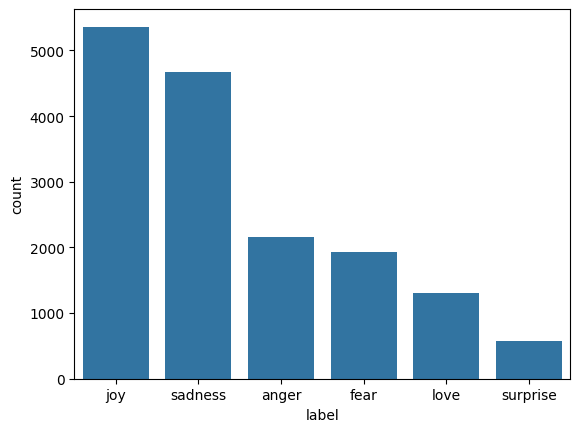

In [ ]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

### Data Preprocessing - Using NLP

Tokenize text, pad sequences to max length 50, and convert labels to NumPy arrays.

In [ ]:
# !pip install tensorflow

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10000

tokenizer = Tokenizer(num_words = max_words, oov_token = '<unk')
tokenizer.fit_on_texts(df_train['text'])

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(train_sequence, maxlen=50, padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequence, maxlen=50, padding='post', truncating='post')

padded_train_sequence


train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))
num_classes

print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print((f"Max Sentence Length: {padded_train_sequence.shape[1]}"))


Vocabulary Size: 15213
Max Sentence Length: 50


### Shared Training Utility
Compute balanced class weights to handle dataset skew and setup early stopping.

In [ ]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes = np.unique(train_labels),
    y = train_labels
)


class_weight_dict = dict(enumerate(class_weights))

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience = 3,
    restore_best_weights = True
)

### Phase 1 - Plain Foundational Models

Train plain (non-bidirectional) Simple RNN, Standard LSTM, and Satndard GRU Models.

tested RNN

In [ ]:
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

# rnn_model = Sequential([
#     Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
#     SimpleRNN(units=128, return_sequences=True),
#     Dropout(0.5),
#     SimpleRNN(units=64),
#     Dropout(0.5),
#     Dense(units=num_classes, activation='softmax') #Output Layer
# ])

# rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [ ]:
# rnn_model.fit(
#     padded_train_sequence,
#     train_labels,
#     validation_data=(padded_test_sequence, test_labels),
#     epochs = 20,
#     batch_size=32,
#     class_weight=class_weight_dict,
#     callbacks=[early_stopping]
# )

# rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
# print(f"RNN Loss: {rnn_loss}")
# print(f"RNN Accuracy: {rnn_accuracy}")

RNN accuracy is 0.135

### Model 2 - Standard LSTM

Plain stacked Long Short-Term Memory network.

In [ ]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 94s 174ms/step - accuracy: 0.1399 - loss: 1.7952 - val_accuracy: 0.1375 - val_loss: 1.7857
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 84ms/step - accuracy: 0.1563 - loss: 1.7932 - val_accuracy: 0.0850 - val_loss: 1.8225
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.1584 - loss: 1.7884 - val_accuracy: 0.1130 - val_loss: 1.8112
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 84ms/step - accuracy: 0.1870 - loss: 1.6763 - val_accuracy: 0.1735 - val_loss: 1.7588
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 80s 80ms/step - accuracy: 0.3940 - loss: 1.3140 - val_accuracy: 0.2615 - val_loss: 1.5407
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 82ms/step - accuracy: 0.6551 - loss: 0.8006 - val_accuracy: 0.7445 - val_loss: 0.8346
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 81ms/step - accuracy: 0.8103 - loss: 0.5433 - val_accuracy: 0.8355 - val_loss: 0.6164
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 81ms/step - accuracy: 0.8617 - loss: 0.4266 -